# Invoice Payment Prediction — Exploratory Data Analysis

**Project:** Invoice Payment Prediction  
**Analysis dataset:** 1,048,575 training invoices  
**Notebook purpose:** Explore payment status, invoice values, payment timing, customer behaviour, aging proxies, time trends, and numerical relationships.

## 1. Objectives
1. Understand invoice payment-status distribution.
2. Examine invoice amounts and paid-invoice payment timing.
3. Analyse payment terms, customer behaviour, country patterns, and time trends.
4. Explore outstanding-invoice aging using a clearly stated dataset reference date.
5. Identify relationships and formulate testable machine-learning hypotheses.

## 2. Important data limitations
- No paid invoice in this dataset has a positive payment delay. Therefore, the data does **not** provide examples of paid-late invoices.
- `payment_date` is future information for a prediction made at invoice creation. Do not use it as a feature for invoice-time prediction.
- `is_overdue` is derived from `payment_status`; using it to predict payment status/overdue status causes target leakage.
- Monetary fields contain multiple currencies. Combined totals and distributions are not single-currency financial values.
- For non-paid invoices, `payment_date` equals `due_date` in the supplied data. Treat it as a placeholder, not proof that an unpaid invoice was paid on its due date.
- The aging analysis uses the latest due date in the dataset as a reference date. It is a dataset-based proxy, **not** a verified current aging snapshot.
- The full dataset is required to reproduce all analyses. The public sample CSV has customer identifiers removed, so customer-level analysis may be unavailable from that sample.

## 3. Load libraries and data

Set `DATA_PATH` to your local full Parquet file. The path below matches the project folder used during this analysis.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

DATA_PATH = r"C:\invioce_data\deliverables\invoice_eda_dataset.parquet"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Full EDA Parquet file was not found. Download/copy the full dataset "
        "to DATA_PATH. The small public sample is not a full replacement."
    )

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Date columns:")
print(df[["invoice_date", "due_date", "payment_date"]].dtypes)

Dataset shape: (1048575, 37)
Missing values: 0
Date columns:
invoice_date    datetime64[ns]
due_date        datetime64[ns]
payment_date    datetime64[ns]
dtype: object


### Dataset validation

The expected local EDA dataset contains 1,048,575 rows and 37 columns, with no missing values. The six derived columns were validated against their source dates before this notebook was prepared.

In [2]:
expected_shape = (1_048_575, 37)
print("Expected shape:", expected_shape)
print("Actual shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))

required_columns = [
    "invoice_date", "due_date", "payment_date", "payment_status",
    "total_amount", "payment_terms_days", "invoice_year_month",
    "customer_country", "is_month_end"
]
missing_columns = [c for c in required_columns if c not in df.columns]
print("Missing required columns:", missing_columns)

assert not missing_columns, f"Missing required columns: {missing_columns}"
assert df["invoice_date"].notna().all()
assert df["due_date"].notna().all()

Expected shape: (1048575, 37)
Actual shape: (1048575, 37)
Missing values: 0
Missing required columns: []


## 4. Prepare analysis fields

Payment delay is calculated only for paid invoices:
- Negative value = paid before due date
- Zero = paid on due date
- Positive value = paid after due date

`days_to_pay` is the number of days between invoice date and payment date.

In [3]:
paid_df = df.loc[df["payment_status"].eq("Paid")].copy()

paid_df["payment_delay_days"] = (
    paid_df["payment_date"] - paid_df["due_date"]
).dt.days

paid_df["days_to_pay"] = (
    paid_df["payment_date"] - paid_df["invoice_date"]
).dt.days

print("Paid invoices:", len(paid_df))
print("Paid invoices with positive delay:",
      int((paid_df["payment_delay_days"] > 0).sum()))
print("Payment delay summary:")
display(paid_df["payment_delay_days"].describe())

Paid invoices: 713456
Paid invoices with positive delay: 0
Payment delay summary:


count    713456.000000
mean        -15.027684
std          12.147261
min         -60.000000
25%         -22.000000
50%         -12.000000
75%          -6.000000
max           0.000000
Name: payment_delay_days, dtype: float64

## 5. Univariate analysis

### Chart 1 — Invoice payment status distribution

Shows the count of invoices in each payment status. The chart describes the supplied training dataset; it does not establish future payment outcomes.

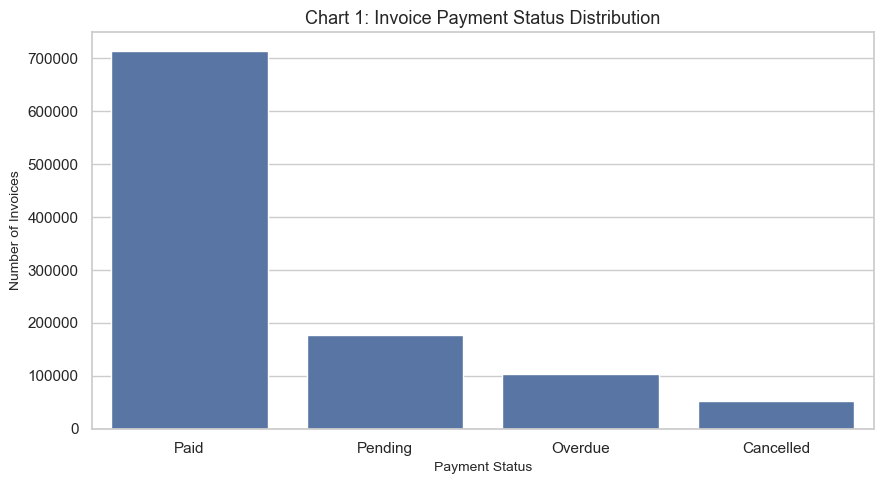

In [4]:
status_counts = df["payment_status"].value_counts().reindex(
    ["Paid", "Pending", "Overdue", "Cancelled"]
)

plt.figure(figsize=(9, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title("Chart 1: Invoice Payment Status Distribution")
plt.xlabel("Payment Status")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()

### Chart 2 — Invoice amount distribution

The distribution is strongly right-skewed. Because currencies are mixed, interpret this as a distribution of recorded numeric amounts, not one consolidated currency value.

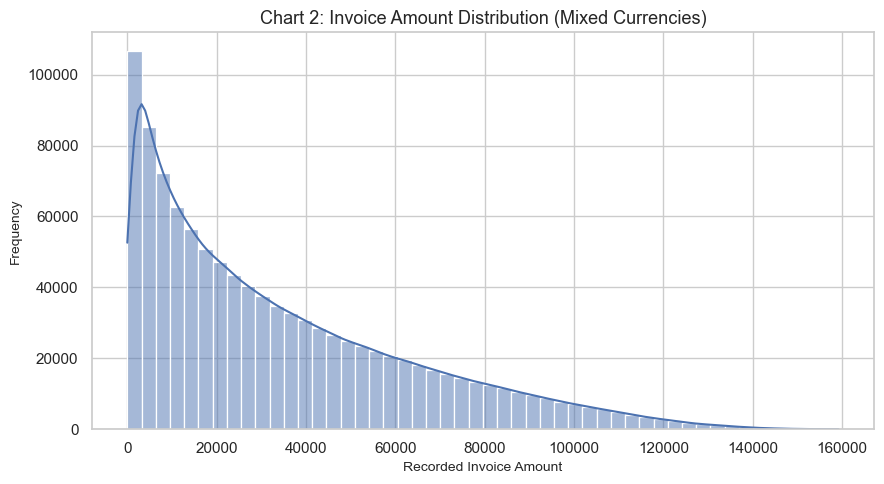

In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(df["total_amount"], bins=50, kde=True)
plt.title("Chart 2: Invoice Amount Distribution (Mixed Currencies)")
plt.xlabel("Recorded Invoice Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Chart 3 — Payment delay distribution for paid invoices

All observed paid-invoice delays are zero or negative. This dataset therefore cannot teach a model what a genuinely late paid invoice looks like.

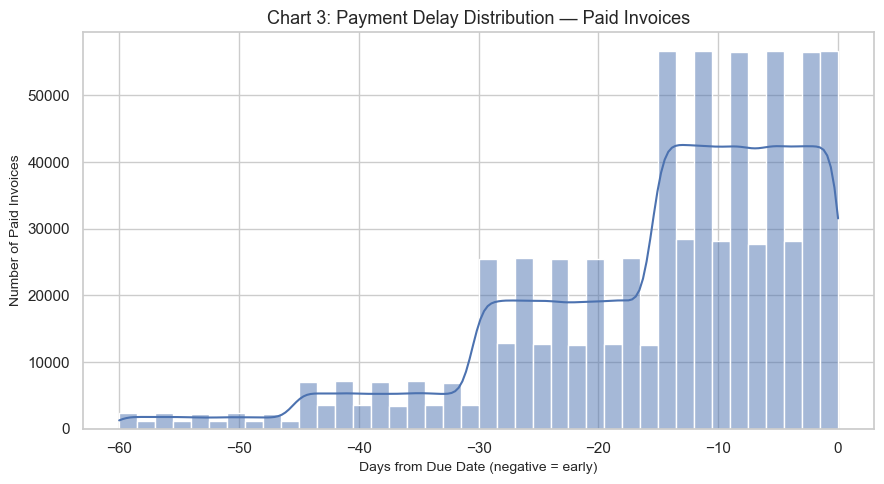

In [6]:
plt.figure(figsize=(9, 5))
sns.histplot(paid_df["payment_delay_days"], bins=40, kde=True)
plt.title("Chart 3: Payment Delay Distribution — Paid Invoices")
plt.xlabel("Days from Due Date (negative = early)")
plt.ylabel("Number of Paid Invoices")
plt.tight_layout()
plt.show()

### Chart 4 — Days to pay distribution

Shows the elapsed time from invoice date to payment date among paid invoices.

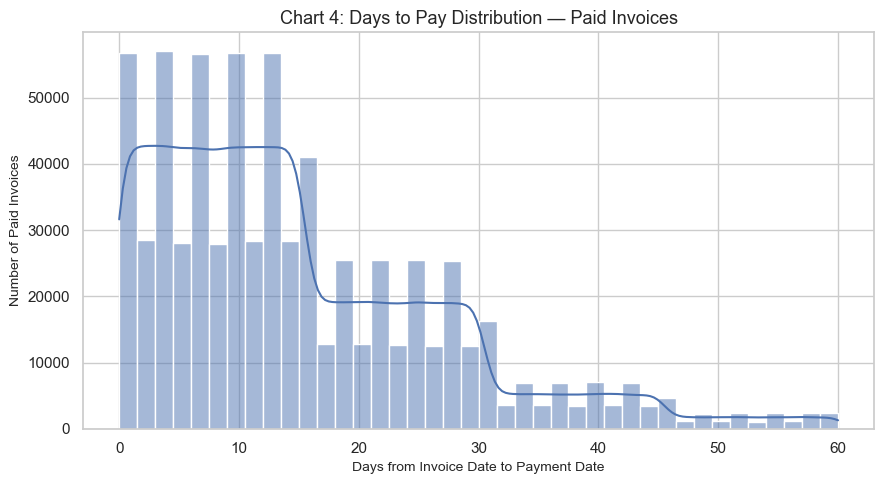

In [7]:
plt.figure(figsize=(9, 5))
sns.histplot(paid_df["days_to_pay"], bins=40, kde=True)
plt.title("Chart 4: Days to Pay Distribution — Paid Invoices")
plt.xlabel("Days from Invoice Date to Payment Date")
plt.ylabel("Number of Paid Invoices")
plt.tight_layout()
plt.show()

## 6. Bivariate analysis

### Chart 5 — Invoice amount vs payment delay

A deterministic random sample of up to 10,000 paid invoices is plotted for readability. Earlier analysis found essentially zero correlation between amount and payment delay (Pearson ≈ 0.0006; Spearman ≈ 0.0005). Amounts are in mixed currencies.

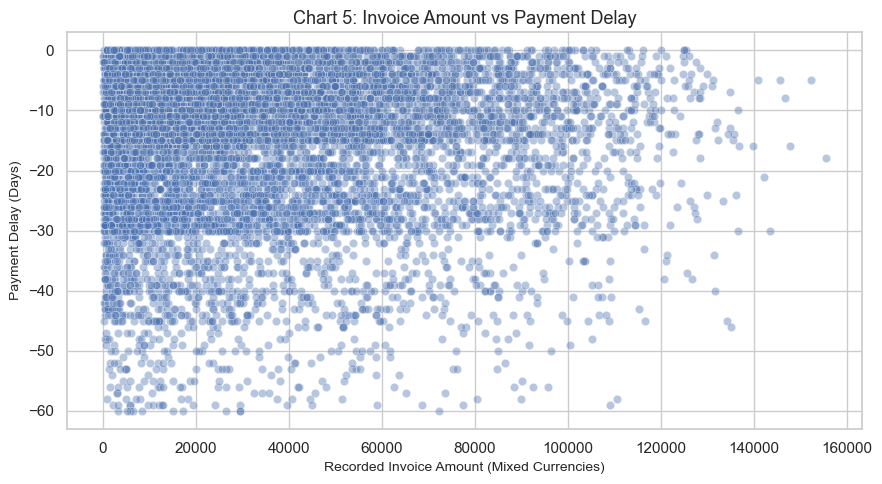

In [8]:
scatter_sample = paid_df.sample(
    n=min(10_000, len(paid_df)), random_state=42
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=scatter_sample,
    x="total_amount",
    y="payment_delay_days",
    alpha=0.4
)
plt.title("Chart 5: Invoice Amount vs Payment Delay")
plt.xlabel("Recorded Invoice Amount (Mixed Currencies)")
plt.ylabel("Payment Delay (Days)")
plt.tight_layout()
plt.show()

### Chart 6 — Payment terms vs payment delay

Longer payment terms are associated with more negative payment delays in this dataset. This is an association, not proof that longer terms cause earlier payment.

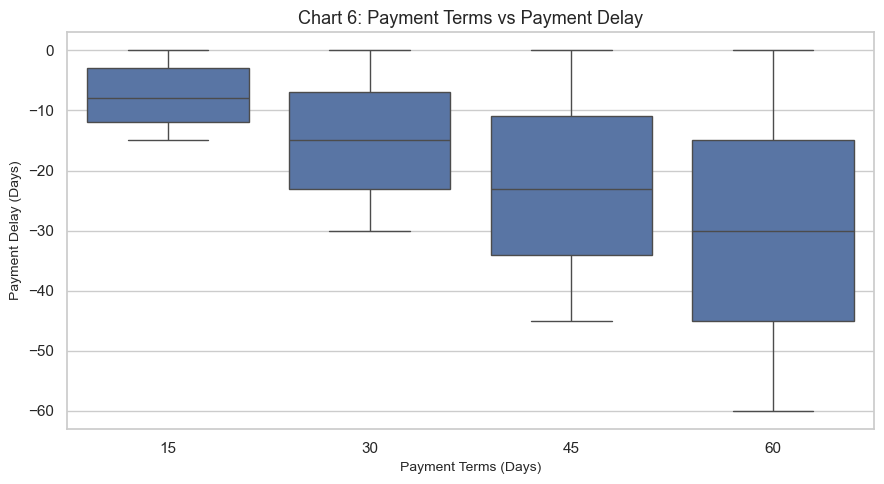

In [9]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=paid_df,
    x="payment_terms_days",
    y="payment_delay_days"
)
plt.title("Chart 6: Payment Terms vs Payment Delay")
plt.xlabel("Payment Terms (Days)")
plt.ylabel("Payment Delay (Days)")
plt.tight_layout()
plt.show()

## 7. Time-based analysis

### Chart 7 — Monthly invoice volume

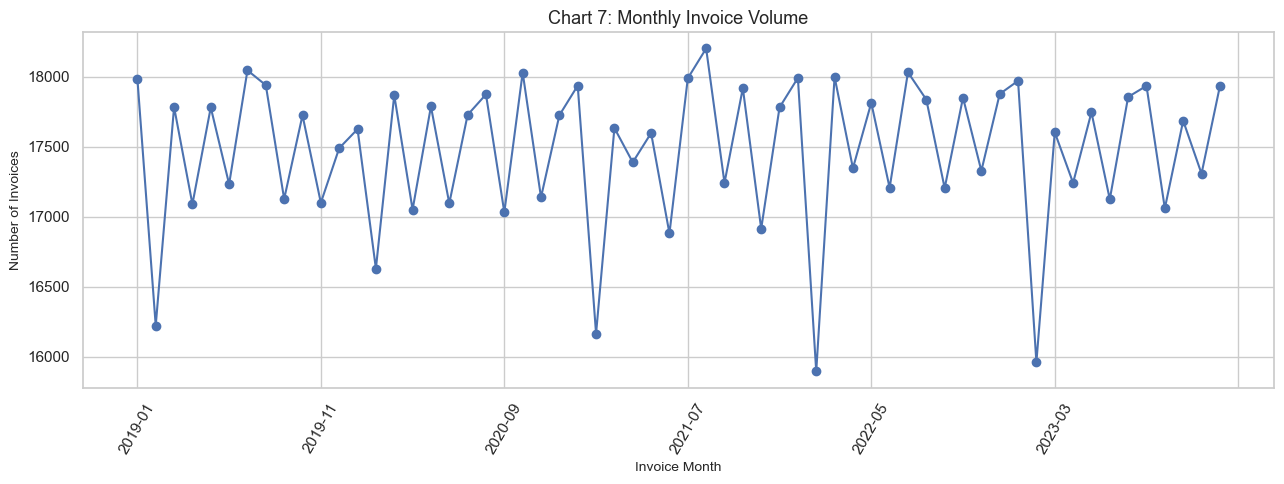

In [10]:
monthly_volume = df.groupby("invoice_year_month").size()
monthly_volume.index = monthly_volume.index.astype(str)

plt.figure(figsize=(13, 5))
monthly_volume.plot(kind="line", marker="o")
plt.title("Chart 7: Monthly Invoice Volume")
plt.xlabel("Invoice Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

### Chart 8 — Monthly average payment delay

The average delay remains close to -15 days across months. This chart is calculated only from paid invoices.

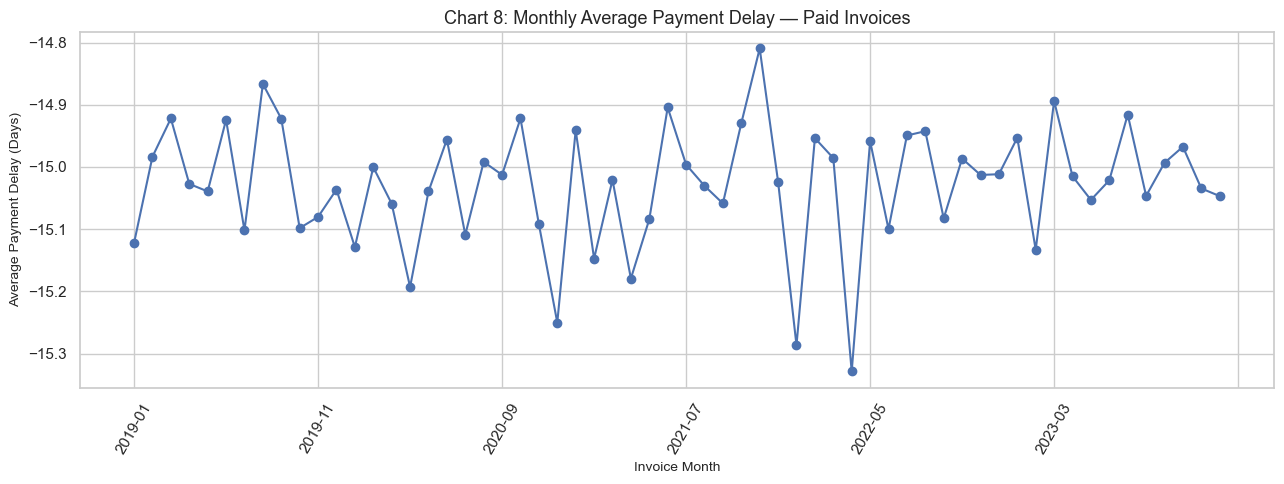

In [11]:
monthly_delay = (
    paid_df.groupby("invoice_year_month")["payment_delay_days"].mean()
)
monthly_delay.index = monthly_delay.index.astype(str)

plt.figure(figsize=(13, 5))
monthly_delay.plot(kind="line", marker="o")
plt.title("Chart 8: Monthly Average Payment Delay — Paid Invoices")
plt.xlabel("Invoice Month")
plt.ylabel("Average Payment Delay (Days)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

## 8. Country and customer analysis

### Chart 9 — Average payment delay by country

Country averages are close to one another in this dataset. These are descriptive comparisons, not evidence that geography has no effect in other populations.

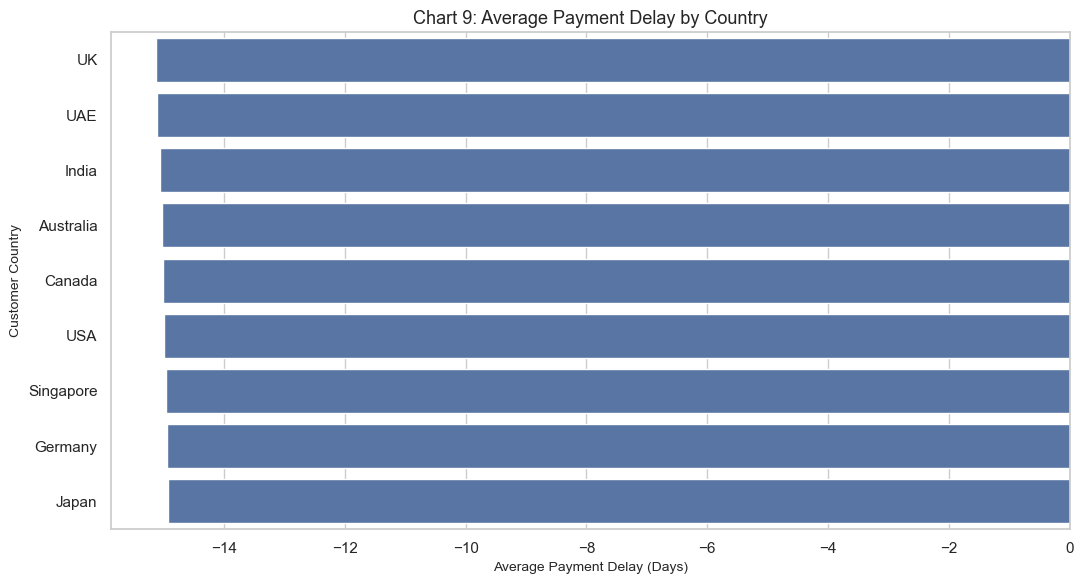

In [12]:
country_delay = (
    paid_df.groupby("customer_country")["payment_delay_days"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(11, 6))
sns.barplot(x=country_delay.values, y=country_delay.index)
plt.title("Chart 9: Average Payment Delay by Country")
plt.xlabel("Average Payment Delay (Days)")
plt.ylabel("Customer Country")
plt.tight_layout()
plt.show()

### Chart 10 — Customer early-payment behaviour

Only customers with at least 10 paid invoices are included. Customer IDs are used only for grouping and are not displayed in the chart. This analysis requires the full dataset because the public sample removes customer identifiers.

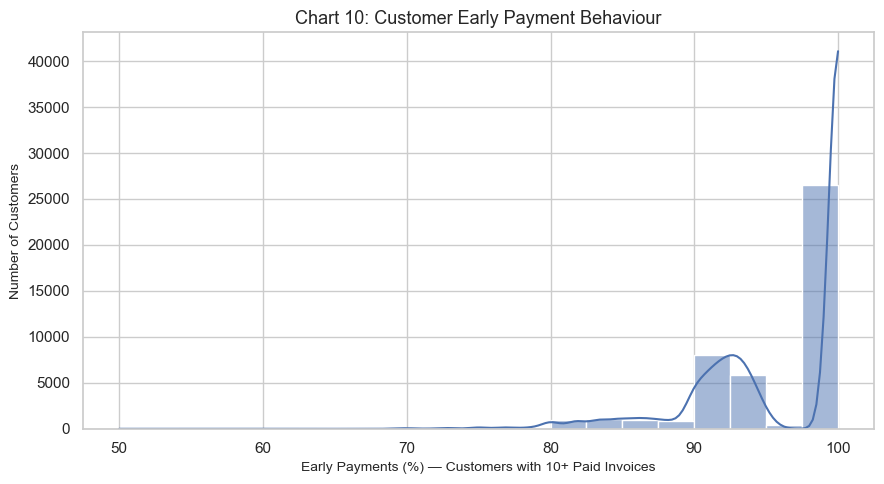

In [13]:
if "customer_id" in paid_df.columns:
    customer_behaviour = (
        paid_df.groupby("customer_id")
        .agg(
            total_paid=("payment_status", "size"),
            early_payments=("payment_delay_days", lambda x: (x < 0).sum()),
            on_time_payments=("payment_delay_days", lambda x: (x == 0).sum())
        )
    )

    customer_behaviour = customer_behaviour[
        customer_behaviour["total_paid"] >= 10
    ].copy()

    customer_behaviour["early_share"] = (
        customer_behaviour["early_payments"]
        / customer_behaviour["total_paid"] * 100
    )

    plt.figure(figsize=(9, 5))
    sns.histplot(customer_behaviour["early_share"], bins=20, kde=True)
    plt.title("Chart 10: Customer Early Payment Behaviour")
    plt.xlabel("Early Payments (%) — Customers with 10+ Paid Invoices")
    plt.ylabel("Number of Customers")
    plt.tight_layout()
    plt.show()
else:
    print("Chart 10 skipped: customer_id is not available in this dataset.")

## 9. Outstanding-invoice aging proxy

**Reference date:** latest due date in the dataset. The calculation measures elapsed time from each outstanding invoice's due date to that reference date. It is not a verified current aging report.

### Chart 11 — Invoice aging distribution

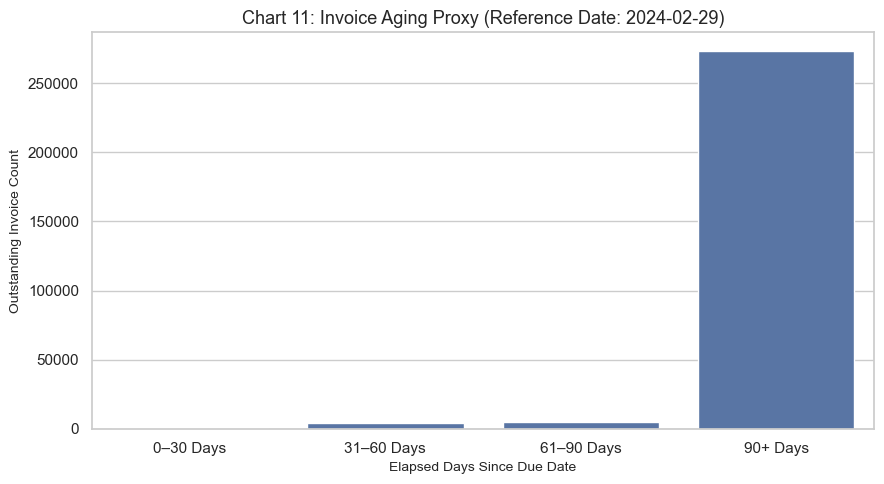

In [14]:
report_date = df["due_date"].max()

outstanding_df = df[
    df["payment_status"].isin(["Pending", "Overdue"])
].copy()

outstanding_df["days_overdue"] = (
    report_date - outstanding_df["due_date"]
).dt.days

aging_bins = [-1, 30, 60, 90, np.inf]
aging_labels = ["0–30 Days", "31–60 Days", "61–90 Days", "90+ Days"]

outstanding_df["aging_bucket"] = pd.cut(
    outstanding_df["days_overdue"],
    bins=aging_bins,
    labels=aging_labels
)

aging_counts = (
    outstanding_df["aging_bucket"]
    .value_counts()
    .reindex(aging_labels, fill_value=0)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=aging_counts.index, y=aging_counts.values)
plt.title(
    f"Chart 11: Invoice Aging Proxy (Reference Date: {report_date.date()})"
)
plt.xlabel("Elapsed Days Since Due Date")
plt.ylabel("Outstanding Invoice Count")
plt.tight_layout()
plt.show()

### Chart 12 — Aging bucket vs payment status

The large Pending count in older buckets highlights why this aging calculation must be described as a dataset-based proxy rather than a reliable live receivables aging report.

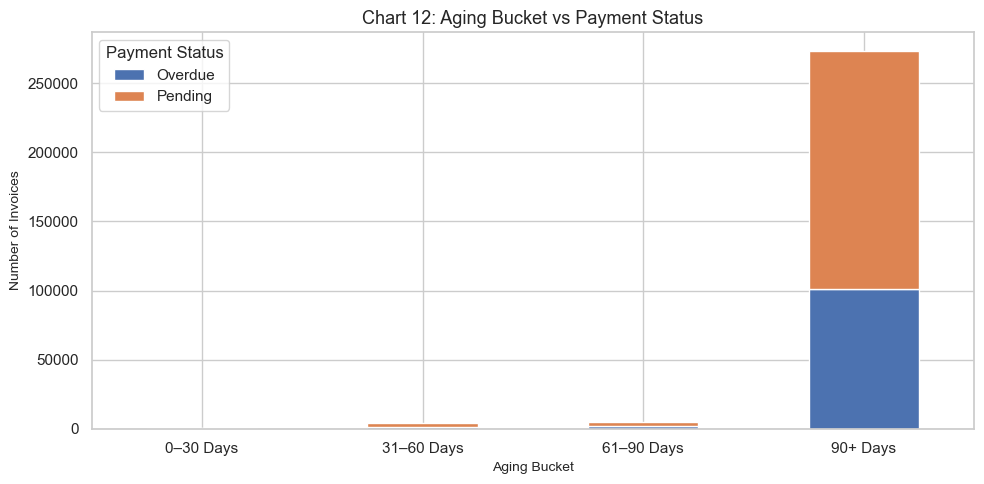

In [15]:
aging_status = pd.crosstab(
    outstanding_df["aging_bucket"],
    outstanding_df["payment_status"]
).reindex(aging_labels, fill_value=0)

aging_status.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Chart 12: Aging Bucket vs Payment Status")
plt.xlabel("Aging Bucket")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=0)
plt.legend(title="Payment Status")
plt.tight_layout()
plt.show()

## 10. Correlation and month-end analysis

### Chart 13 — Numerical correlation heatmap

Several high correlations are expected because subtotal, discount, tax, and total amount are mathematically related. Correlation does not establish causation. These related amount fields may also create multicollinearity in a model.

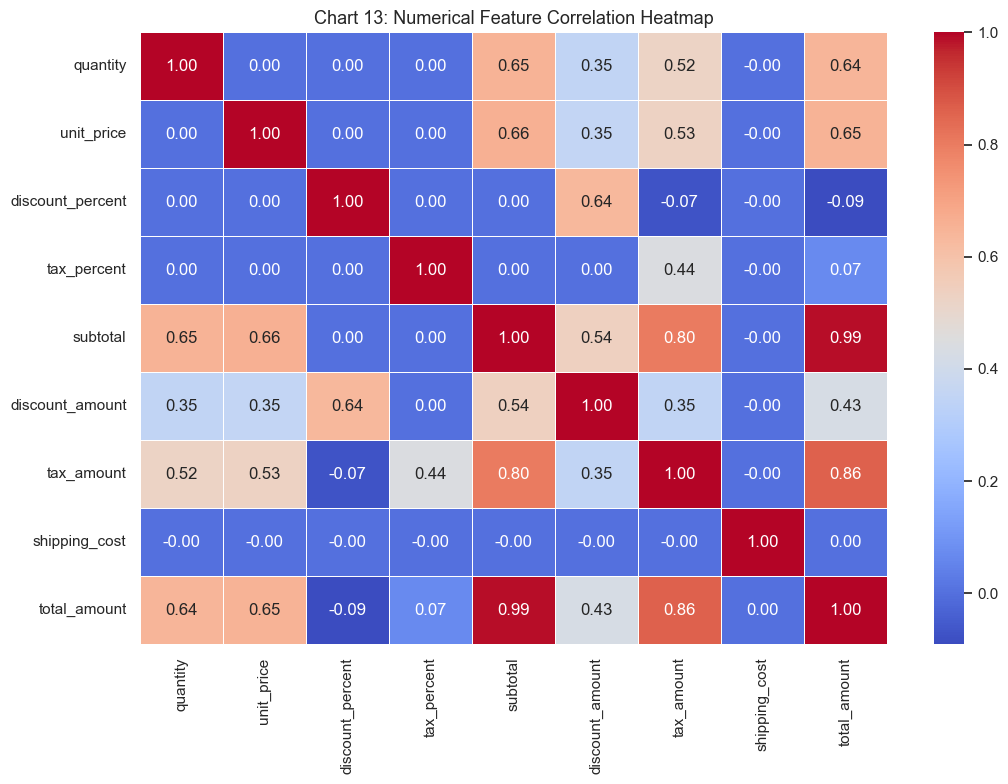

In [16]:
correlation_columns = [
    "quantity", "unit_price", "discount_percent", "tax_percent",
    "subtotal", "discount_amount", "tax_amount", "shipping_cost",
    "total_amount"
]

correlation_matrix = df[correlation_columns].corr(method="pearson")

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Chart 13: Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Chart 14 — Average daily invoice volume: month-end vs regular days

The final five calendar days of each month are compared with all other days using **average invoices per calendar day**, not raw totals. This avoids comparing groups with unequal numbers of days.

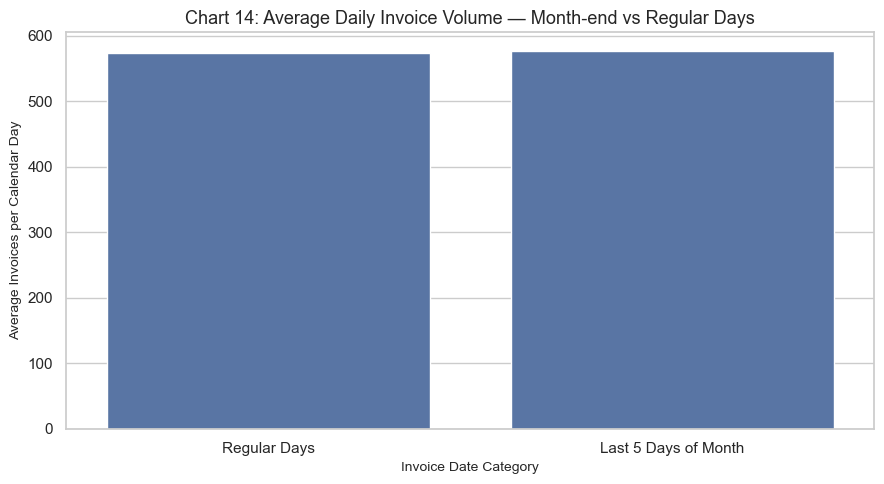

is_month_end
Regular Days            573.81
Last 5 Days of Month    576.45
Name: invoice_count, dtype: float64


In [17]:
daily_counts = (
    df.groupby(["invoice_date", "is_month_end"])
    .size()
    .reset_index(name="invoice_count")
)

month_end_daily_average = (
    daily_counts.groupby("is_month_end")["invoice_count"].mean()
    .rename(index={
        False: "Regular Days",
        True: "Last 5 Days of Month"
    })
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=month_end_daily_average.index,
    y=month_end_daily_average.values
)
plt.title("Chart 14: Average Daily Invoice Volume — Month-end vs Regular Days")
plt.xlabel("Invoice Date Category")
plt.ylabel("Average Invoices per Calendar Day")
plt.tight_layout()
plt.show()

print(month_end_daily_average.round(2))

## 11. Key findings, business interpretations, and ML hypotheses

The following insights summarize the full-dataset analysis completed for this project. Hypotheses are proposals to test during modelling; they are not proven model results.

| # | Chart-backed finding | Business interpretation | ML hypothesis to test |
|---|---|---|---|
| 1 | **Chart 1:** Paid 68.04%, Pending 16.99%, Overdue 9.95%, Cancelled 5.02%. | Most records are paid, while pending and overdue invoices form a material outstanding group. | Test a status-classification baseline, but define the prediction time and exclude leakage fields. |
| 2 | **Chart 3:** 96.03% of paid invoices are early, 3.97% on time, and 0% late. | The paid subset contains no late-payment examples; it cannot support learning the characteristics of late paid invoices. | Obtain genuine late-payment examples before training a late-payment classifier. |
| 3 | **Chart 5:** Amount-delay correlation is effectively zero (Pearson ≈ 0.0006; Spearman ≈ 0.0005). | Invoice amount alone has little observed association with paid-invoice delay here. Mixed currencies also limit amount comparisons. | Test amount only alongside currency-aware features and other invoice/customer variables. |
| 4 | **Chart 6:** Payment terms and delay are negatively correlated (Pearson ≈ -0.5865). | Longer terms are associated with payments occurring further ahead of the due date in this dataset. | Payment terms may be useful, but validate on a chronological holdout and investigate how due dates are assigned. |
| 5 | **Chart 9:** Country-level average delays are all close to -15 days. | The observed country differences are small relative to the overall pattern. | Test whether country adds measurable predictive value beyond terms and customer history. |
| 6 | **Chart 10:** Among 45,048 repeat customers with at least 10 paid invoices, average early-payment share is 96.03%; late share is 0%. | Repeat customers are predominantly early payers in the observed paid records. | Time-aware historical customer behaviour may help, but compute it using only information available before each invoice. |
| 7 | **Charts 11–12:** 96.65% of outstanding records fall in the 90+ bucket using 2024-02-29 as the reference date. | The dataset's due dates are much older than the chosen reference date; status labels do not align with a live aging snapshot. | Do not use this proxy as a verified target. Obtain a genuine as-of date and reliable payment-state history. |
| 8 | **Charts 7–8:** Monthly volume varies, while average paid-invoice delay stays near -15 days. | Invoice activity changes more than the average payment timing across months. | Calendar features may help volume forecasting; test whether they improve payment prediction out of time. |
| 9 | **Charts 13–14:** Subtotal-total correlation is about 0.988; average daily month-end volume is about 576.45 vs 573.81 on regular days. | Amount components are mathematically related; month-end daily volume difference is small. | Avoid redundant formula-derived features; test month-end indicators rather than assuming a strong month-end effect. |

## 12. Modelling cautions

1. **Target definition first:** Decide whether the model predicts payment status, probability of payment by due date, or days-to-payment. These are different tasks.
2. **Leakage:** Exclude `payment_date` and `is_overdue` for invoice-time prediction. Check every feature for information that would only be known after invoice creation.
3. **Late-payment class:** The paid subset has zero positive delay values. A model trained on this data cannot learn a meaningful late-paid class.
4. **Time split:** Prefer chronological train/validation/test splits over random splits for future prediction.
5. **Customer history:** Build lagged features using only invoices dated before the invoice being scored.
6. **Currency:** Group by currency or convert using documented exchange rates before comparing monetary amounts.
7. **Aging:** Replace the dataset-based aging proxy with a verified reporting date and trustworthy outstanding status before using it operationally.

## 13. Conclusion

The EDA shows that paid invoices are overwhelmingly recorded as paid before their due dates, payment terms have a notable association with payment delay, and invoice amount has almost no observed relationship with delay in this dataset. Country and calendar patterns are comparatively stable. The aging output requires caution because it is based on a dataset reference date and does not align cleanly with payment-status labels.

The largest modelling limitation is the absence of paid-late examples. Before building a late-payment prediction model, the project needs reliable historical examples of invoices actually paid after their due dates, a clear prediction timestamp, and leakage-safe features.